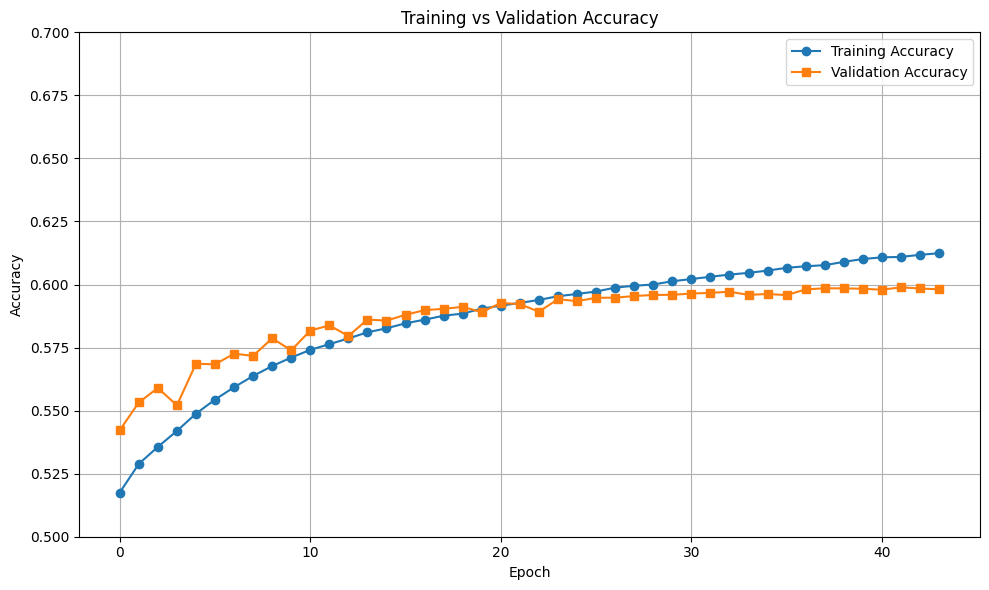

In [3]:
import re
import matplotlib.pyplot as plt

# Path to the log file
log_path = "dropout0.75log"  # change this to your actual file path

# Storage for accuracies
train_acc = []
val_acc = []

# Patterns to extract accy
train_pattern = re.compile(r"^{.*'epoch': (\d+),.*'accy': ([0-9.]+),.*'MCC'")
val_pattern = re.compile(r"^{'epoch': (\d+),.*'accy': ([0-9.]+),.*'MCC'")

# Read and parse
with open(log_path, 'r') as f:
    lines = f.readlines()

i = 0
while i < len(lines):
    line = lines[i].strip()
    
    # Match training accy line
    if line.startswith("{'epoch':") and 'train' in lines[i - 1]:
        match = train_pattern.match(line)
        if match:
            train_acc.append(float(match.group(2)))

    # Match validation accy line
    elif line.startswith("{'epoch':") and 'validate' in lines[i - 1]:
        match = val_pattern.match(line)
        if match:
            val_acc.append(float(match.group(2)))
    
    i += 1

# Sanity check
assert len(train_acc) == len(val_acc), "Mismatch in training and validation epochs"

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(train_acc, label="Training Accuracy", marker='o')
plt.plot(val_acc, label="Validation Accuracy", marker='s')
plt.ylim(0.5, 0.7)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
